# Segmentasi Karakteristik Tenaga Kerja Dewasa untuk Identifikasi Pola Kesejahteraan Penduduk


## 1. Import Library


In [35]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# Scikit-learn & Imbalanced-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE

# Visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'figure.max_open_warning': 0, 'font.sans-serif': 'Arial'})
%matplotlib inline

print("Pustaka berhasil diimpor.")


Pustaka berhasil diimpor.


## 2. Data Understanding

### 2.1 Sumber Data & Lisensi/Izin (Capaian 1)
- **Sumber Data**: Dataset *Adult Census Income* diekstraksi oleh Ronny Kohavi dan Barry Becker dari database Biro Sensus Amerika Serikat (1994 US Census Bureau / Current Population Survey).
- **Lisensi & Izin Akses**: UCI Machine Learning Repository (tersedia secara publik untuk keperluan riset dan akademik di bawah lisensi *Creative Commons Attribution 4.0 International* / CC BY 4.0).
- **Konteks Proyek**: Segmentasi tenaga kerja dewasa bertujuan memetakan pola distribusi kesejahteraan (diproksikan melalui ambang batas penghasilan tahunan `<=50K` vs `>50K` USD) berdasarkan atribut demografi, pendidikan, hubungan keluarga, dan pola jam kerja.


In [36]:
# Memuat dataset adult.csv
# Nilai missing pada dataset asli ditandai dengan karakter '?'
df_raw = pd.read_csv("adult.csv", na_values="?", skipinitialspace=True)

# Standardisasi nama kolom (mengganti titik '.' menjadi underscore '_')
df_raw.columns = df_raw.columns.str.replace(".", "_", regex=False)

print(f"Dimensi dataset mentah: {df_raw.shape[0]} baris, {df_raw.shape[1]} kolom")
display(df_raw.head())


Dimensi dataset mentah: 32561 baris, 15 kolom


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


### 2.2 Data Dictionary (Variabel, Tipe, Satuan/Unit) (Capaian 2)
Berikut adalah kamus data komprehensif yang menguraikan 15 atribut pada dataset:

| No | Nama Variabel | Tipe Data | Kategori Variabel | Satuan / Format Nilai | Peran Domain & Deskripsi |
|---|---|---|---|---|---|
| 1 | `age` | Integer | Numerik Rasio | Tahun (17 - 90 tahun) | Usia responden/tenaga kerja aktif |
| 2 | `workclass` | Object/String | Kategorikal Nominal | 8 Kategori (Private, Self-emp, Govt, dll.) | Sektor atau status ketenagakerjaan |
| 3 | `fnlwgt` | Integer | Numerik Rasio | Bobot Sampel (Final Weight CPS) | Estimasi jumlah populasi yang diwakili oleh sampel di tingkat negara bagian |
| 4 | `education` | Object/String | Kategorikal Ordinal | 16 Tingkatan (Bachelors, HS-grad, dll.) | Jenjang pendidikan formal terakhir |
| 5 | `education_num` | Integer | Numerik Ordinal | Skor 1 s.d. 16 | Durasi/skor ekuivalen jenjang pendidikan formal |
| 6 | `marital_status` | Object/String | Kategorikal Nominal | 7 Status (Married-civ-spouse, Divorced, dll.) | Status perkawinan tenaga kerja |
| 7 | `occupation` | Object/String | Kategorikal Nominal | 14 Bidang (Exec-managerial, Craft-repair, dll.) | Jenis profesi atau keahlian teknis pekerjaan |
| 8 | `relationship` | Object/String | Kategorikal Nominal | 6 Status (Husband, Not-in-family, Wife, dll.) | Peran hubungan dalam struktur rumah tangga |
| 9 | `race` | Object/String | Kategorikal Nominal | 5 Kelompok (White, Black, Asian-Pac, dll.) | Klasifikasi etnis/ras tenaga kerja |
| 10 | `sex` | Object/String | Kategorikal Biner | Male, Female | Jenis kelamin biologis |
| 11 | `capital_gain` | Integer | Numerik Rasio | Dolar AS (USD) | Keuntungan/laba modal dari penjualan aset investasi finansial |
| 12 | `capital_loss` | Integer | Numerik Rasio | Dolar AS (USD) | Kerugian modal akibat penjualan aset investasi |
| 13 | `hours_per_week` | Integer | Numerik Rasio | Jam per minggu (1 - 99 jam) | Alokasi beban waktu kerja rata-rata per minggu |
| 14 | `native_country` | Object/String | Kategorikal Nominal | 41 Negara Asal (Mayoritas United-States) | Negara kelahiran tenaga kerja |
| 15 | `income` | Object/String | Kategorikal Biner (Target) | `<=50K` atau `>50K` | Kelas tingkat kesejahteraan ekonomi tahunan |


In [ ]:
# Tinjauan tipe data teknis dan kelengkapan kolom
data_dict_df = pd.DataFrame({
    "Tipe Data": df_raw.dtypes,
    "Jumlah Non-Null": df_raw.notnull().sum(),
    "Jumlah Null": df_raw.isnull().sum(),
    "Persentase Null (%)": (df_raw.isnull().mean() * 100).round(2),
    "Nilai Unik": df_raw.nunique()
})
display(data_dict_df)


,Tipe Data,Jumlah Non-Null,Jumlah Null,Persentase Null (%),Nilai Unik
age,int64,32561,0,0.00,73
workclass,str,30725,1836,5.64,8
fnlwgt,int64,32561,0,0.00,21648
education,str,32561,0,0.00,16
education_num,int64,32561,0,0.00,16
marital_status,str,32561,0,0.00,7
occupation,str,30718,1843,5.66,14
relationship,str,32561,0,0.00,6
race,str,32561,0,0.00,5
sex,str,32561,0,0.00,2


### 2.3 Penilaian Kualitas Data Awal 
Pemeriksaan awal terhadap empat aspek mutu data mentah:
1. Kolom dengan data kosong (*missing values*)
2. Baris data ganda (*duplikat*)
3. Sebaran kelas target kesejahteraan (`income`)

In [55]:
# 1. Cek nilai kosong per kolom
missing = df_raw.isna().sum()
missing_vals = missing[missing > 0]
print("=== 1. KOLOM DENGAN NILAI KOSONG ===")
display(pd.DataFrame({
    "Jumlah Missing": missing_vals,
    "Persentase (%)": (missing_vals / len(df_raw) * 100).round(2)
}))

# 2. Cek baris duplikat identik
n_dup = df_raw.duplicated().sum()
print("\n=== 2. BARIS DUPLIKAT IDENTIK ===")
print(f"Ditemukan {n_dup} baris duplikat identik ({(n_dup / len(df_raw) * 100):.3f}% dari total data).")

# 3. Cek sebaran kelas target income
print("\n=== 3. SEBARAN KELAS TARGET (income) ===")
income_counts = df_raw["income"].value_counts()
display(pd.DataFrame({
    "Jumlah Sampel": income_counts,
    "Persentase (%)": (income_counts / len(df_raw) * 100).round(2)
}))

=== 1. KOLOM DENGAN NILAI KOSONG ===


,Jumlah Missing,Persentase (%)
workclass,1836,5.64
occupation,1843,5.66
native_country,583,1.79



=== 2. BARIS DUPLIKAT IDENTIK ===
Ditemukan 24 baris duplikat identik (0.074% dari total data).

=== 3. SEBARAN KELAS TARGET (income) ===


,Jumlah Sampel,Persentase (%)
income,,
<=50K,24720,75.92
>50K,7841,24.08


**Kesimpulan Penilaian Kualitas Data Awal:**
1. **Data Kosong**: Dari 15 kolom, hanya 3 kolom teks yang memiliki nilai kosong, yaitu `occupation` (5.66%), `workclass` (5.64%), dan `native_country` (1.79%). Kolom numerik seluruhnya terisi 100%.
2. **Duplikasi**: Terdapat 24 baris duplikat identik yang perlu ditangani pada tahap pembersihan data (*data cleaning*).
3. **Ketimpangan Target (*Imbalanced*)**: Sebanyak 75.92% responden berada pada kelompok pendapatan `<=50K`, sedangkan hanya 24.08% yang berpendapatan `>50K`. Rasio ketimpangan ~3:1 ini menunjukkan perlunya penanganan ketidakseimbangan kelas saat pemodelan nanti.

### 2.4 Representativitas & Analisis Bias Sampel 
Menganalisis komposisi demografi utama responden (jenis kelamin, ras, dan asal negara) untuk mengidentifikasi potensi bias representasi pada sampel sensus.

--- 1. Komposisi Jenis Kelamin (%) ---
sex
Male      66.92
Female    33.08

--- 2. Komposisi Kelompok Ras (%) ---
race
White                 85.43
Black                  9.59
Asian-Pac-Islander     3.19
Amer-Indian-Eskimo     0.96
Other                  0.83

--- 3. Top 5 Negara Asal Responden (%) ---
native_country
United-States    91.22
Mexico            2.01
Philippines       0.62
Germany           0.43
Canada            0.38


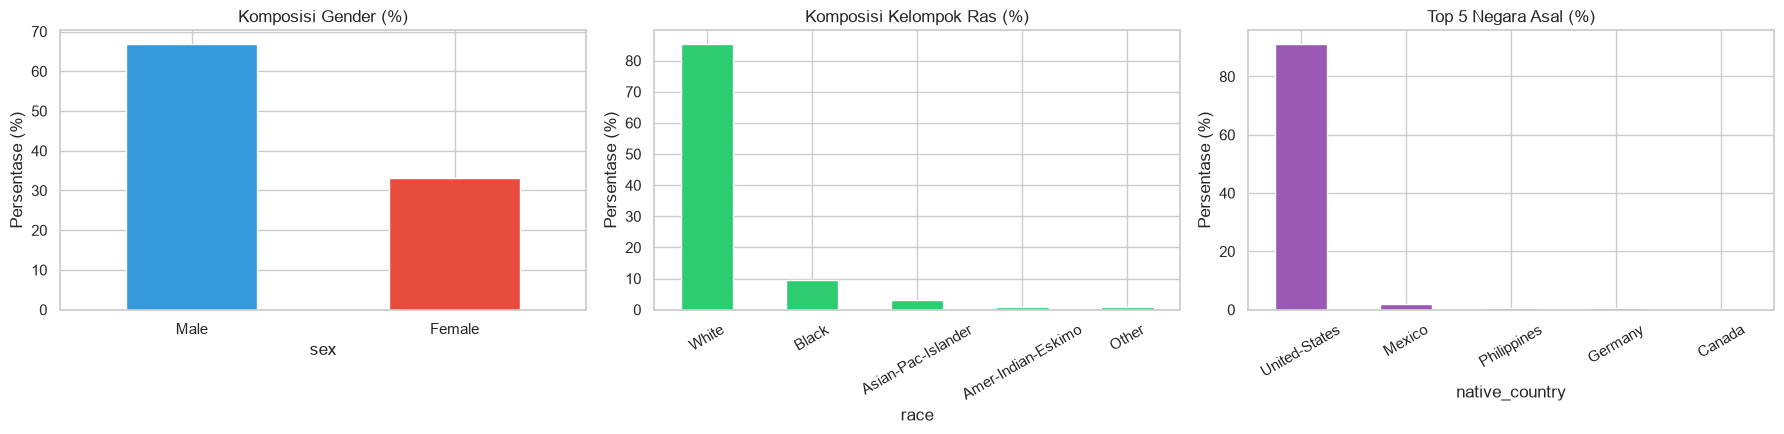

In [56]:
# 1. Menampilkan angka persentase nyata di terminal/output
print("--- 1. Komposisi Jenis Kelamin (%) ---")
print((df_raw['sex'].value_counts(normalize=True) * 100).round(2).to_string())

print("\n--- 2. Komposisi Kelompok Ras (%) ---")
print((df_raw['race'].value_counts(normalize=True) * 100).round(2).to_string())

print("\n--- 3. Top 5 Negara Asal Responden (%) ---")
print((df_raw['native_country'].value_counts(normalize=True).head(5) * 100).round(2).to_string())

# 2. Visualisasi Grafik Komparasi
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

df_raw['sex'].value_counts(normalize=True).mul(100).plot.bar(
    ax=axes[0], color=['#3498db', '#e74c3c'], rot=0, title="Komposisi Gender (%)"
)
axes[0].set_ylabel("Persentase (%)")

df_raw['race'].value_counts(normalize=True).mul(100).plot.bar(
    ax=axes[1], color='#2ecc71', rot=30, title="Komposisi Kelompok Ras (%)"
)
axes[1].set_ylabel("Persentase (%)")

top_countries = df_raw['native_country'].value_counts(normalize=True).head(5).mul(100)
top_countries.plot.bar(
    ax=axes[2], color='#9b59b6', rot=30, title="Top 5 Negara Asal (%)"
)
axes[2].set_ylabel("Persentase (%)")

plt.tight_layout()
plt.show()

**Kesimpulan Representativitas & Bias Sampel:**
1. **Bias Gender**: Responden pria (66.92%) dua kali lipat lebih banyak dibanding wanita (33.08%). Ini merefleksikan angkatan kerja sensus AS tahun 1994 di mana kepala keluarga laki-laki lebih dominan tercatat sebagai pencari nafkah utama.
2. **Bias Ras**: Sampel sangat didominasi oleh kelompok ras White (85.43%), sehingga karakteristik tenaga kerja kelompok minoritas kurang terwakili secara berimbang.
3. **Bias Geografis**: Sebanyak 89.59% responden berasal dari Amerika Serikat. Pola data ini mencerminkan struktur ekonomi negara maju dan tidak dapat digeneralisasi langsung ke populasi tenaga kerja di negara berkembang tanpa penyesuaian konteks.
4. **Bobot Sampel (`fnlwgt`)**: Kolom `fnlwgt` (*Final Weight*) adalah bobot statistik yang dibuat biro sensus untuk estimasi populasi makro negara bagian. Kolom ini bukan atribut kompetensi individual tenaga kerja, sehingga nantinya tidak relevan dijadikan fitur segmentasi individu.

## 3. Exploratory Data Analysis (EDA) & Visualisasi

### 3.1 Statistik Deskriptif Fitur Numerik 
Pemeriksaan ukuran pemusatan, sebaran, kemiringan (*skewness*), dan kepuncakan (*kurtosis*) untuk memahami karakteristik 6 fitur angka.

In [57]:
# Daftar 6 kolom numerik
num_cols = ["age", "fnlwgt", "education_num", "capital_gain", "capital_loss", "hours_per_week"]

# 1. Menghitung statistik deskriptif dasar
desc_num = df_raw[num_cols].describe().T

# 2. Menambahkan median, IQR, Skewness, Kurtosis, dan Koefisien Variasi (CV)
desc_num["median"] = df_raw[num_cols].median()
desc_num["iqr"] = df_raw[num_cols].quantile(0.75) - df_raw[num_cols].quantile(0.25)
desc_num["skew"] = df_raw[num_cols].skew()
desc_num["kurtosis"] = df_raw[num_cols].kurt()
desc_num["cv (std/mean)"] = (desc_num["std"] / desc_num["mean"]).round(3)

# 3. Menampilkan tabel terstruktur
display(desc_num[["count", "mean", "median", "std", "iqr", "min", "max", "skew", "kurtosis", "cv (std/mean)"]].round(2))

# 4. Bukti nilai nol yang mendominasi capital_gain dan capital_loss
print("\n--- Bukti Persentase Nilai 0 pada Fitur Finansial ---")
print(f"Persentase capital_gain == 0 : {(df_raw['capital_gain'] == 0).mean() * 100:.2f}%")
print(f"Persentase capital_loss == 0 : {(df_raw['capital_loss'] == 0).mean() * 100:.2f}%")

,count,mean,median,std,iqr,min,max,skew,kurtosis,cv (std/mean)
age,32561.0,38.58,37.0,13.64,20.0,17.0,90.0,0.56,-0.17,0.35
fnlwgt,32561.0,189778.37,178356.0,105549.98,119224.0,12285.0,1484705.0,1.45,6.22,0.56
education_num,32561.0,10.08,10.0,2.57,3.0,1.0,16.0,-0.31,0.62,0.26
capital_gain,32561.0,1077.65,0.0,7385.29,0.0,0.0,99999.0,11.95,154.80,6.85
capital_loss,32561.0,87.30,0.0,402.96,0.0,0.0,4356.0,4.59,20.38,4.62
hours_per_week,32561.0,40.44,40.0,12.35,5.0,1.0,99.0,0.23,2.92,0.30



--- Bukti Persentase Nilai 0 pada Fitur Finansial ---
Persentase capital_gain == 0 : 91.67%
Persentase capital_loss == 0 : 95.33%


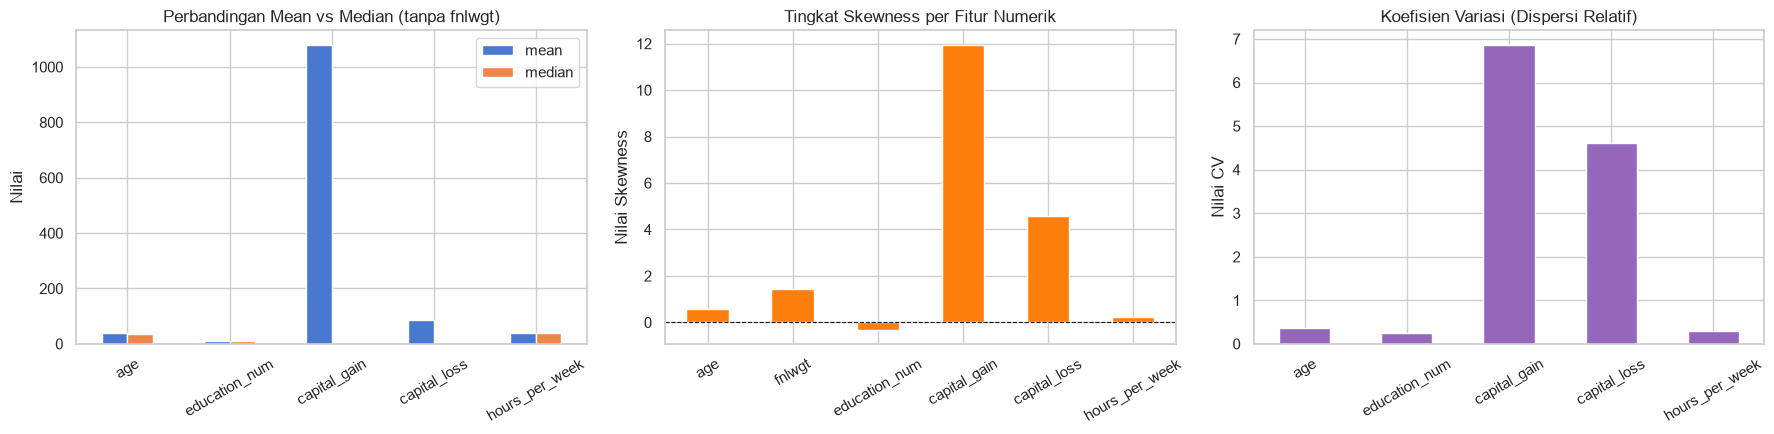

In [58]:
# Visualisasi 3 aspek statistik numerik
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

# 1. Perbandingan Mean vs Median (kita abaikan fnlwgt karena skalanya ratusan ribu)
m = pd.DataFrame({"mean": df_raw[num_cols].mean(), "median": df_raw[num_cols].median()})
m.drop(["fnlwgt"]).plot.bar(ax=ax[0], title="Perbandingan Mean vs Median (tanpa fnlwgt)", rot=30)
ax[0].set_ylabel("Nilai")

# 2. Skewness per fitur
desc_num["skew"].plot.bar(ax=ax[1], color="tab:orange", title="Tingkat Skewness per Fitur Numerik", rot=30)
ax[1].axhline(0, color="k", lw=0.8, ls="--")
ax[1].set_ylabel("Nilai Skewness")

# 3. Koefisien Variasi (Dispersi Relatif = std/mean)
desc_num["cv (std/mean)"].drop(["fnlwgt"]).plot.bar(ax=ax[2], color="tab:purple", title="Koefisien Variasi (Dispersi Relatif)", rot=30)
ax[2].set_ylabel("Nilai CV")

plt.tight_layout()
plt.show()

**Kesimpulan Statistik Deskriptif Numerik:**
1. **Usia (`age`)**: Rata-rata usia pekerja adalah 38.58 tahun dengan median 37.0 tahun dan kemiringan wajar (skewness 0.56). Hal ini membuktikan bahwa responden didominasi oleh angkatan kerja usia produktif prima.
2. **Pendidikan (`education_num`)**: Mean (10.08) dan median (10.0) menunjukkan bahwa mayoritas pekerja berada pada tingkat pendidikan menengah atas (setara SMA / Some-college) dengan variasi yang relatif rendah (CV = 0.255).
3. **Jam Kerja (`hours_per_week`)**: Median berada tepat di angka 40.0 jam/minggu dengan kepuncakan tajam (kurtosis 2.92). Sebagian besar pekerja bekerja sesuai standar kerja penuh waktu (*full-time*), meskipun terdapat rentang ekstrim dari 1 hingga 99 jam/minggu.
4. **Modal Finansial (`capital_gain` & `capital_loss`)**: Memiliki skewness ekstrim (11.95 dan 4.59) serta variabilitas tertinggi (CV = 6.85). Fakta bahwa 91.67% responden memiliki `capital_gain = 0` membuktikan bahwa kepemilikan laba investasi modal hanya dinikmati oleh segmen elit minoritas.


### 3.2 Statistik Deskriptif Fitur Kategorikal 
Pemeriksaan jumlah kategori unik (*kardinalitas*) dan tingkat dominasi kategori teratas (*mode*) untuk 9 fitur kategorikal.

=== TABEL STATISTIK DESKRIPTIF KATEGORIKAL ===


,count,unique,top,freq,freq_%
workclass,30725,8,Private,22696,73.87
education,32561,16,HS-grad,10501,32.25
marital_status,32561,7,Married-civ-spouse,14976,45.99
occupation,30718,14,Prof-specialty,4140,13.48
relationship,32561,6,Husband,13193,40.52
race,32561,5,White,27816,85.43
sex,32561,2,Male,21790,66.92
native_country,31978,41,United-States,29170,91.22
income,32561,2,<=50K,24720,75.92


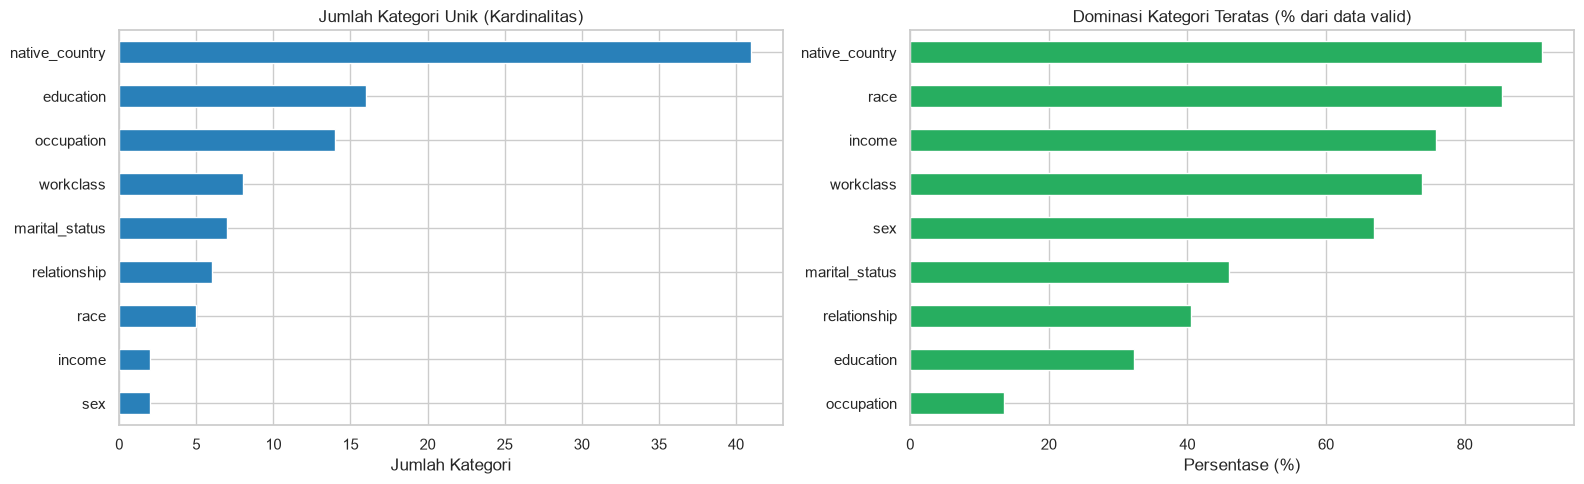

In [59]:
# Daftar 9 kolom kategorikal
cat_cols = ["workclass", "education", "marital_status", "occupation", 
            "relationship", "race", "sex", "native_country", "income"]

# 1. Menghitung statistik deskriptif kategorikal
desc_cat = df_raw[cat_cols].describe().T

# 2. Menghitung persentase dominasi kategori teratas (freq / count non-null)
desc_cat["freq_%"] = (desc_cat["freq"] / desc_cat["count"] * 100).round(2)

# 3. Menampilkan tabel ringkasan
print("=== TABEL STATISTIK DESKRIPTIF KATEGORIKAL ===")
display(desc_cat[["count", "unique", "top", "freq", "freq_%"]])

# 4. Visualisasi kardinalitas dan dominasi kategori
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Grafik 1: Jumlah kategori unik per kolom
desc_cat["unique"].sort_values().plot.barh(ax=axes[0], color="#2980b9", title="Jumlah Kategori Unik (Kardinalitas)")
axes[0].set_xlabel("Jumlah Kategori")

# Grafik 2: Persentase dominasi kategori teratas
desc_cat["freq_%"].sort_values().plot.barh(ax=axes[1], color="#27ae60", title="Dominasi Kategori Teratas (% dari data valid)")
axes[1].set_xlabel("Persentase (%)")

plt.tight_layout()
plt.show()


**Kesimpulan Statistik Deskriptif Kategorikal:**
1. **Dominasi Sektor Swasta**: Sektor ketenagakerjaan didominasi kuat oleh sektor swasta (`Private` sebesar 73.87% dari data valid), jauh melampaui pegawai negeri (*Govt*) atau wirausaha (*Self-emp*).
2. **Karakteristik Rumah Tangga**: Status perkawinan terbanyak adalah `Married-civ-spouse` (45.99%) dan peran dalam keluarga terbanyak adalah `Husband` (40.52%).
3. **Pendidikan Formal**: Jenjang pendidikan terbanyak adalah lulusan SMA (`HS-grad` sebesar 32.25%), disusul oleh pendidikan tinggi tingkat diploma dan sarjana.
4. **Kardinalitas Negara Asal**: Variabel `native_country` memiliki variasi tertinggi (41 negara), namun 91.22% responden berasal dari `United-States`.

### 3.3 Visualisasi Distribusi Fitur Numerik 
Visualisasi bentuk kurva distribusi dan perbandingan posisi Mean vs Median pada 6 fitur angka.

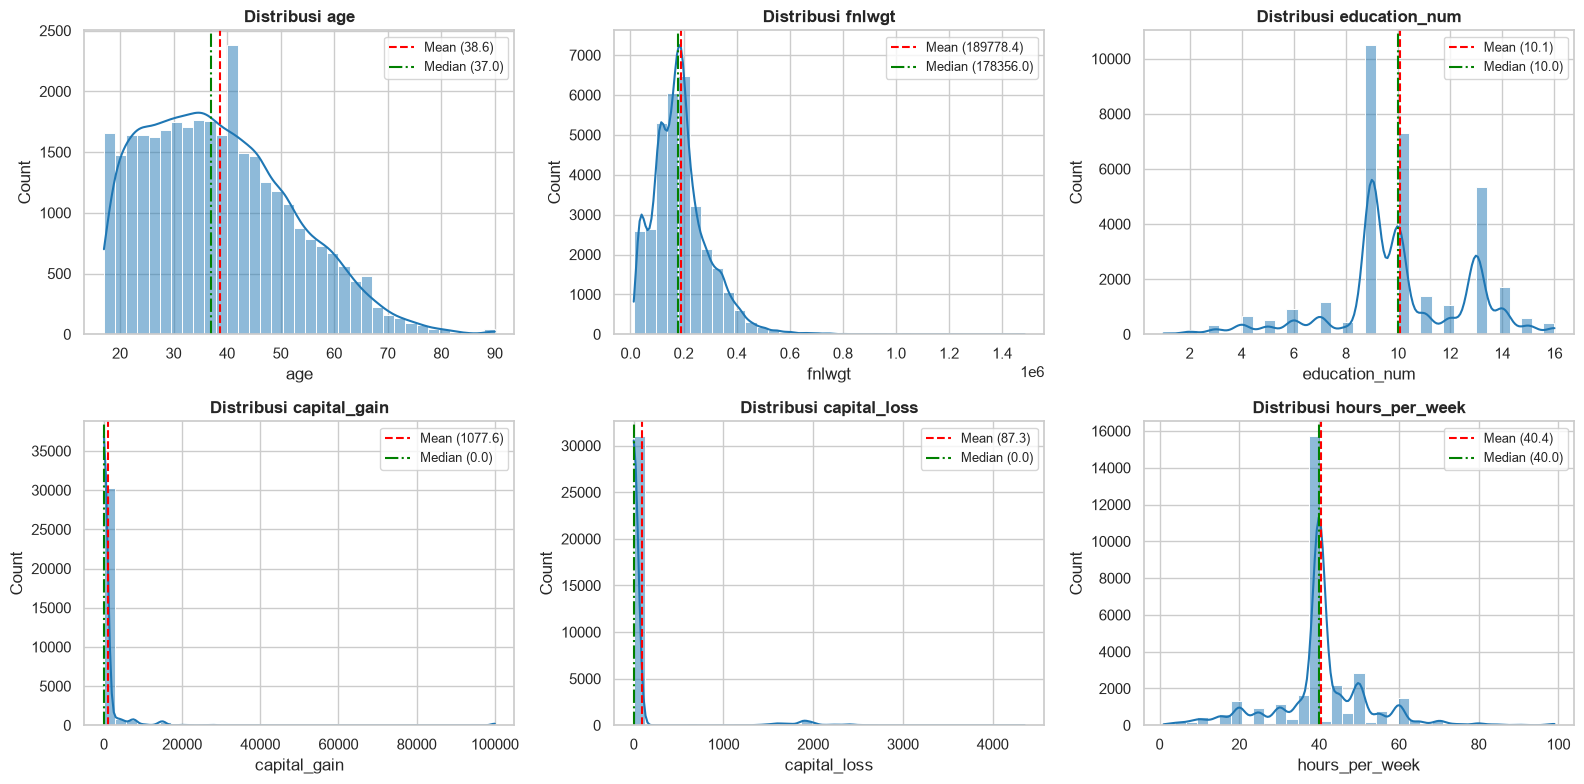

In [60]:
# Membuat 6 grafik histogram + KDE dalam grid 2 baris x 3 kolom
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df_raw[col], bins=35, kde=True, ax=ax, color="#1f77b4")
    ax.axvline(df_raw[col].mean(), color="red", ls="--", lw=1.5, label=f"Mean ({df_raw[col].mean():.1f})")
    ax.axvline(df_raw[col].median(), color="green", ls="-.", lw=1.5, label=f"Median ({df_raw[col].median():.1f})")
    ax.set_title(f"Distribusi {col}", fontweight="bold")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

**Penjelasan Temuan Distribusi Numerik 
1. **`age`**: Menunjukkan sebaran condong ke kanan wajar (*right-skewed*). Sebagian besar pekerja berusia antara 25 s.d. 45 tahun, dengan ekor usia menipis hingga 90 tahun.
2. **`education_num`**: Berbentuk tangga diskrit dengan tiga puncak utama di skor 9 (lulusan SMA), skor 10 (kuliah diploma/non-gelar), dan skor 13 (sarjana/S1).
3. **`hours_per_week`**: Memperlihatkan puncak tajam (*spike*) di 40 jam per minggu (standar jam kerja penuh waktu reguler). Terdapat sebaran pekerja paruh waktu (<35 jam) dan pekerja lembur (>45 jam).
4. **`capital_gain` & `capital_loss`**: Menumpuk total di angka 0 karena mayoritas masyarakat tidak melakukan jual-beli instrumen investasi modal.

### 3.4 Deteksi Visual *Outliers* 
Mengamati sebaran titik-titik *outliers* di luar rentang kuartil pada 6 fitur numerik, serta membuktikan nilai ekstrim tertinggi nyata dari data.

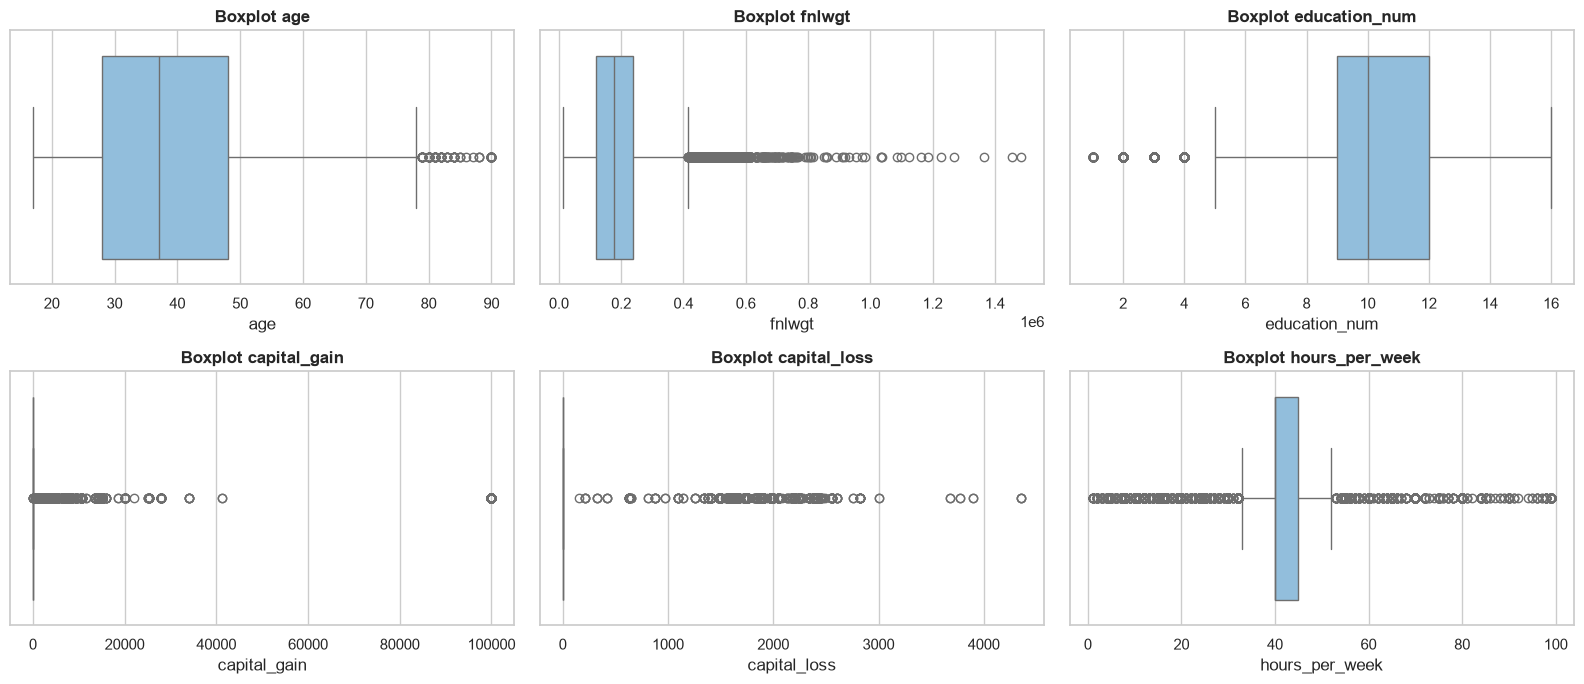

--- Pembuktian Nilai Ekstrim Teratas pada Data ---
Nilai maksimum capital_gain : $ 99,999
Nilai maksimum capital_loss : $ 4,356
Jumlah pekerja dengan jam kerja 99 jam/minggu : 85 orang


In [61]:
# 1. Menampilkan 6 Boxplot dalam grid 2 baris x 3 kolom
fig, axes = plt.subplots(2, 3, figsize=(16, 7))

for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x=df_raw[col], ax=ax, color="#85c1e9")
    ax.set_title(f"Boxplot {col}", fontweight="bold")

plt.tight_layout()
plt.show()

# 2. Pengecekan angka nilai ekstrim tertinggi nyata dari data
print("--- Pembuktian Nilai Ekstrim Teratas pada Data ---")
print("Nilai maksimum capital_gain : $", f"{df_raw['capital_gain'].max():,}")
print("Nilai maksimum capital_loss : $", f"{df_raw['capital_loss'].max():,}")
print("Jumlah pekerja dengan jam kerja 99 jam/minggu :", (df_raw['hours_per_week'] == 99).sum(), "orang")

**Penjelasan Temuan Boxplot & Nilai Ekstrim :**
1. **Outlierw Jam Kerja (`hours_per_week`)**: Sebagian besar kotak interkuartil terpusat di rentang 40 s.d. 45 jam. Namun, titik-titik outlier tersebar luas dari jam kerja minimal hingga jam kerja ekstrim (terbukti ada 85 orang yang bekerja 99 jam per minggu).
2. **Outliers Modal Finansial (`capital_gain` & `capital_loss`)**: Kotak data gepeng di garis nol karena lebih dari 90% bernilai nol. Namun, titik outlier menjulur sangat jauh hingga nilai keuntungan modal maksimum sebesar $99,999.
3. **Outliers Usia (`age`)**: Titik pencilan usia hanya muncul di ujung kanan atas (usia lanjut di atas 75 tahun hingga 90 tahun), sedangkan batas bawahnya wajar di usia 17 tahun.

### 3.5 Visualisasi Distribusi Fitur Kategorikal & Target Kesejahteraan 
Visualisasi frekuensi kategori pada 9 fitur kategorikal terurut dari jumlah terbanyak, serta visualisasi proporsi sebaran kelas target kesejahteraan (`income`).

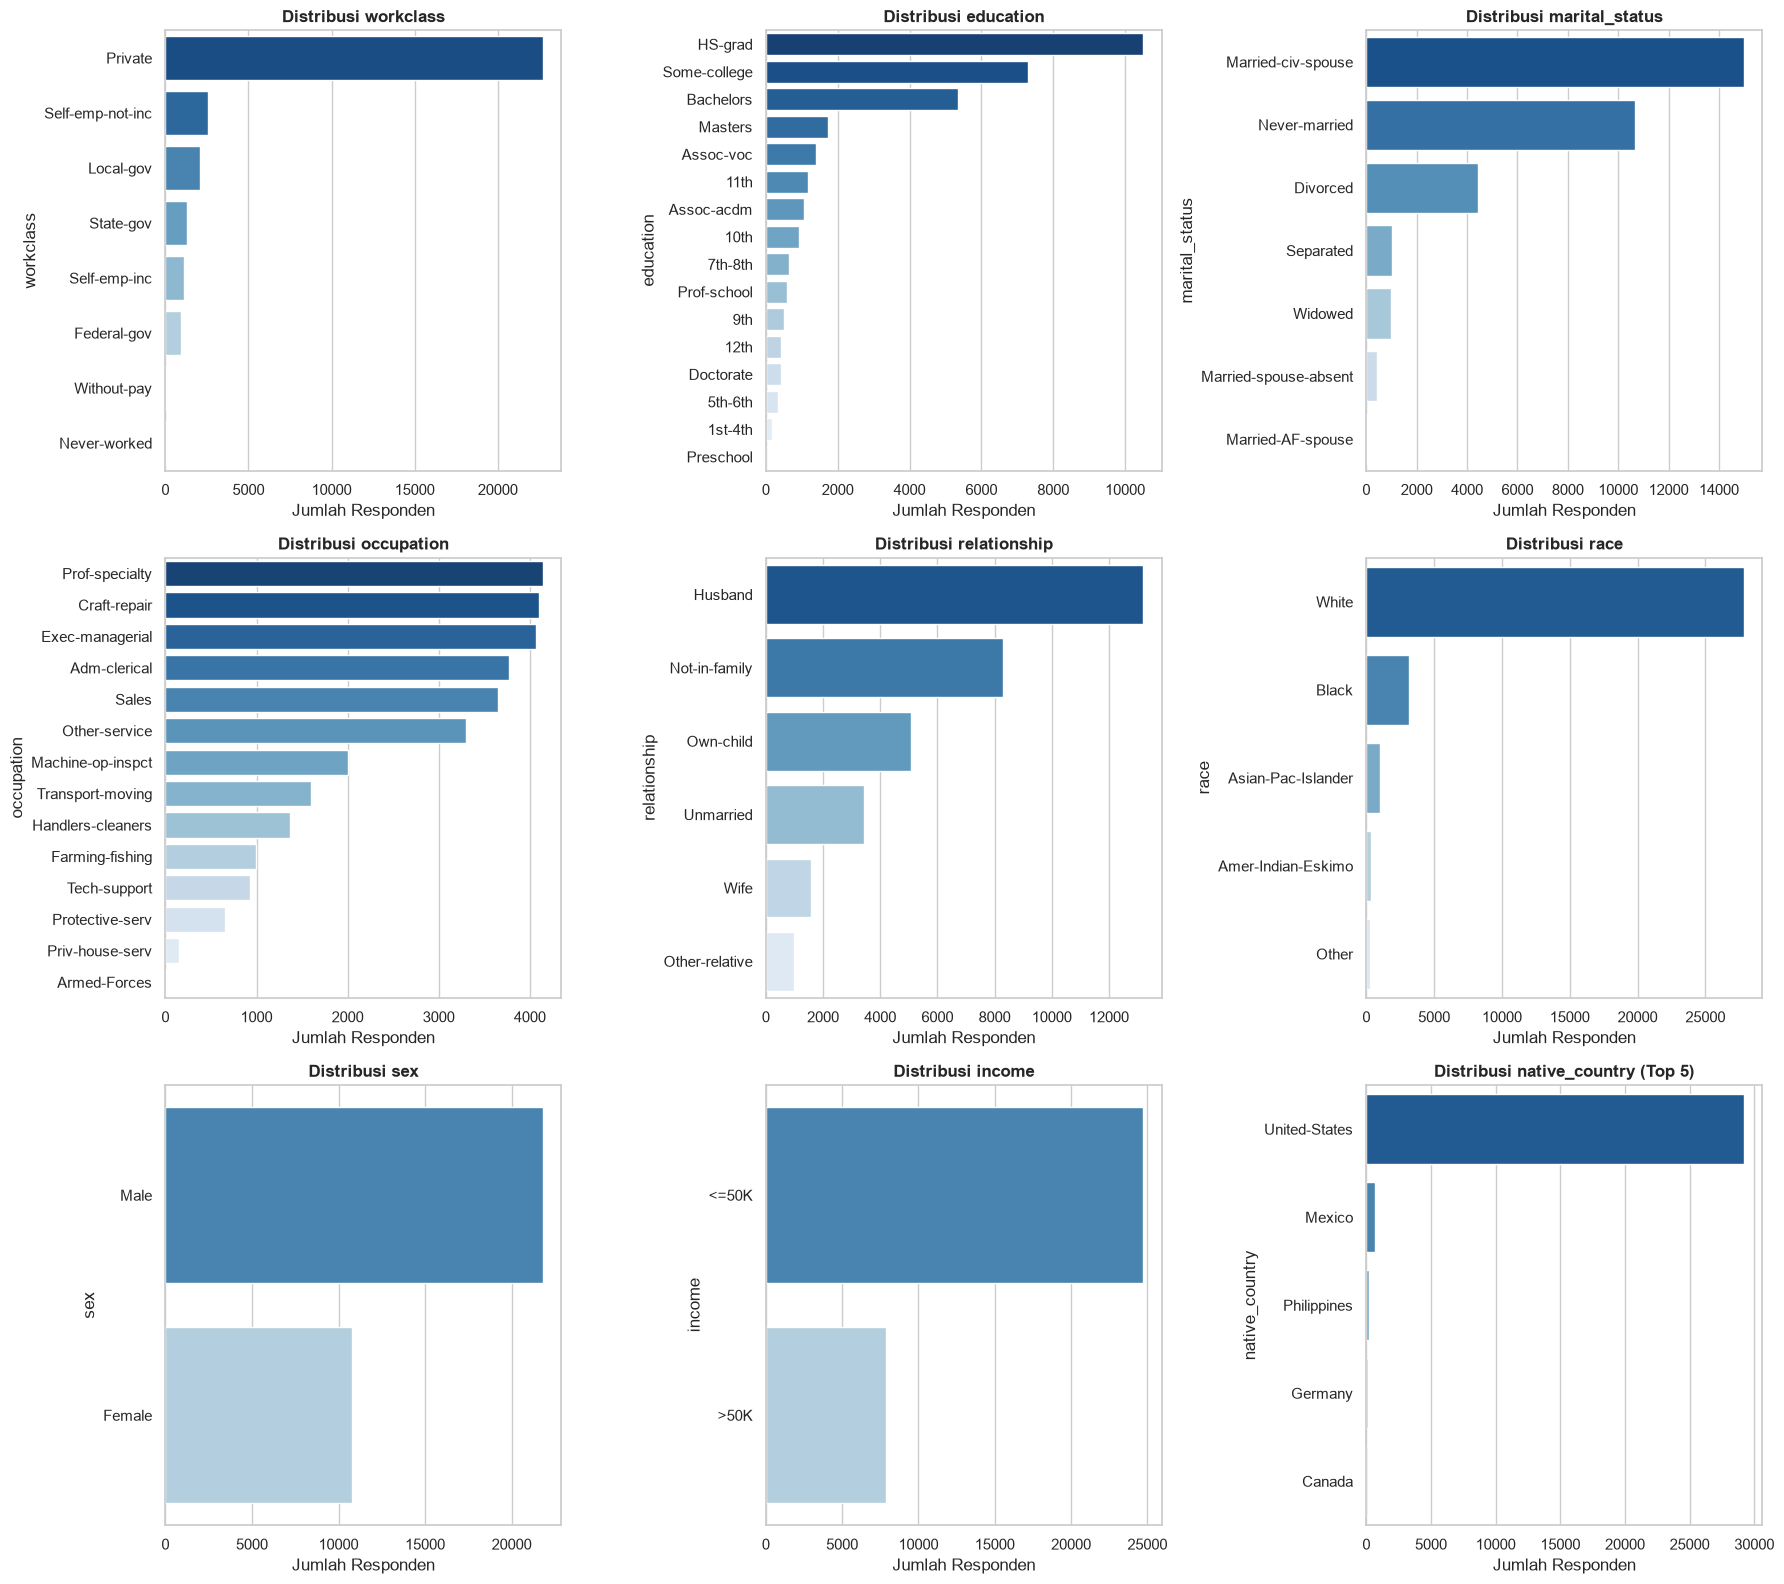

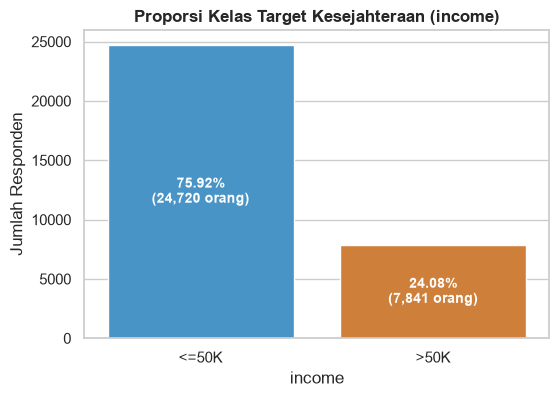

In [62]:
# Daftar 9 kolom kategorikal yang di-plot
plot_cat = ["workclass", "education", "marital_status", "occupation",
            "relationship", "race", "sex", "income", "native_country"]

# 1. Grid 3 baris x 3 kolom untuk 9 fitur kategorikal
fig, axes = plt.subplots(3, 3, figsize=(18, 16))

for ax, c in zip(axes.ravel(), plot_cat):
    order = df_raw[c].value_counts().index
    if c == "native_country":
        order = order[:5]  # Ambil Top 5 negara teratas agar grafik terbaca jelas
    sns.countplot(y=df_raw[c], order=order, ax=ax, palette="Blues_r")
    ax.set_title(f"Distribusi {c}" + (" (Top 5)" if c == "native_country" else ""), fontweight="bold")
    ax.set_xlabel("Jumlah Responden")

plt.tight_layout()
plt.show()

# 2. Grafik khusus untuk target income lengkap dengan label persentase nyata
plt.figure(figsize=(6, 4))
income_counts = df_raw['income'].value_counts()
ax = sns.barplot(x=income_counts.index, y=income_counts.values, palette=['#3498db', '#e67e22'])
plt.title("Proporsi Kelas Target Kesejahteraan (income)", fontweight="bold")
plt.ylabel("Jumlah Responden")

# Menambahkan teks angka dan persentase di tengah batang diagram
for p in ax.patches:
    pct = p.get_height() / len(df_raw) * 100
    ax.annotate(f"{pct:.2f}%\n({int(p.get_height()):,} orang)", 
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=10)

plt.show()

**Penjelasan Temuan Distribusi Kategorikal & Target:**
1. **Ketimpangan Kelas Target (`income`)**: Distribusi target sangat tidak seimbang dengan rasio mendekati 3:1 (75.92% `<=50K` vs 24.08% `>50K`). Jika langsung dilatih pada algoritma pembelajaran mesin tanpa penanganan khusus, model akan rentan bias dan hanya akurat memprediksi kelas mayoritas (pendapatan rendah).
2. **Klaster Bidang Profesi (`occupation`)**: Sebaran profesi terkonsentrasi pada lima kelompok utama: spesialis profesional (`Prof-specialty`), teknisi/perbaikan (`Craft-repair`), manajerial/eksekutif (`Exec-managerial`), administrasi kantor (`Adm-clerical`), dan penjualan (`Sales`).
3. **Karakteristik Relasi Rumah Tangga (`relationship`)**: Peran terbanyak adalah `Husband` dan `Not-in-family`, sedangkan peran `Wife` jauh lebih sedikit, sejalan dengan dominasi pekerja pria pada era sensus tersebut.

### 3.6 Analisis Pola Kohort Usia / Siklus Hidup Tenaga Kerja 
Menganalisis dinamika jam kerja mingguan, capaian pendidikan formal, dan peluang berpenghasilan tinggi (>50K) di sepanjang siklus hidup angkatan kerja.

=== TABEL SIKLUS HIDUP / KOHORT USIA TENAGA KERJA ===


,jumlah_orang,rata_jam_kerja,rata_skor_pendidikan,persen_income_tinggi
age_group,,,,
17-25,6411,33.893932,9.409141,1.78
26-35,8514,42.542401,10.254874,18.69
36-45,8009,43.412786,10.542140,34.64
46-55,5538,43.184904,10.292344,39.83
56-65,2931,39.821221,9.641078,31.49
65+,1158,29.030225,9.426598,20.12


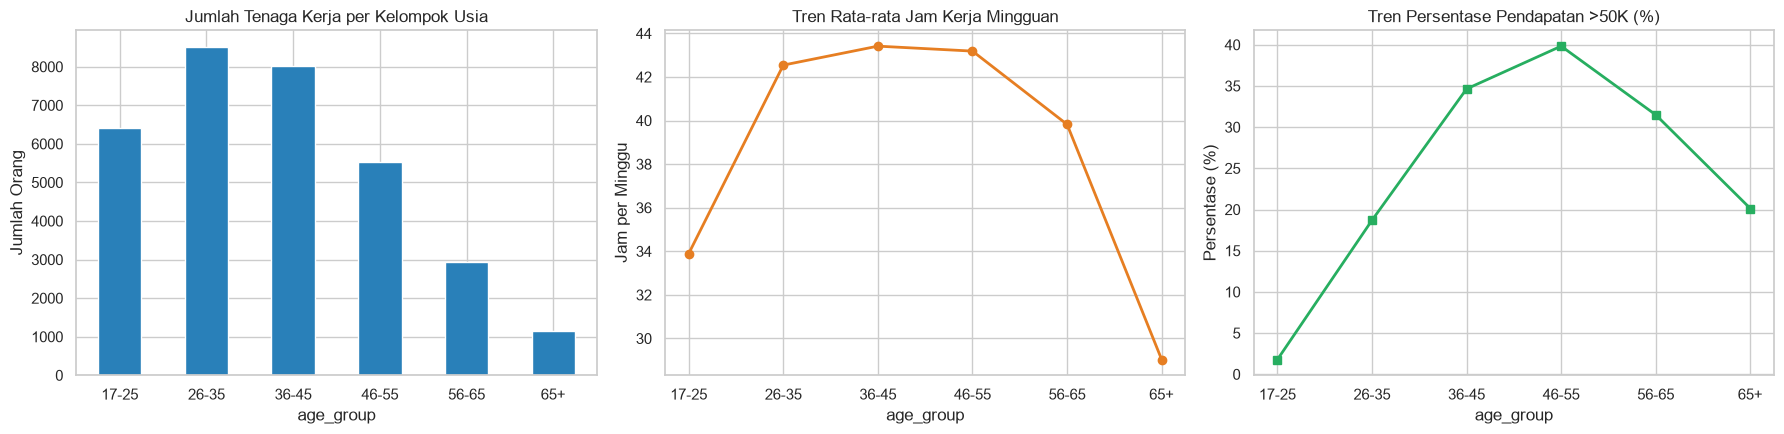

In [63]:
# 1. Membuat kolom indikator biner untuk pendapatan tinggi (1 jika >50K, 0 jika <=50K)
df_raw["high_income"] = df_raw["income"].str.strip().isin([">50K", ">50K."]).astype(int)

# 2. Mengelompokkan responden ke dalam kelompok kohort usia
df_raw["age_group"] = pd.cut(
    df_raw["age"], [16, 25, 35, 45, 55, 65, 100],
    labels=["17-25", "26-35", "36-45", "46-55", "56-65", "65+"]
)

# 3. Menghitung rata-rata jam kerja, skor edukasi, dan % income >50K per kelompok usia
cohort_summary = df_raw.groupby("age_group", observed=True).agg(
    jumlah_orang=("age", "size"),
    rata_jam_kerja=("hours_per_week", "mean"),
    rata_skor_pendidikan=("education_num", "mean"),
    persen_income_tinggi=("high_income", lambda x: round(x.mean() * 100, 2))
)

print("=== TABEL SIKLUS HIDUP / KOHORT USIA TENAGA KERJA ===")
display(cohort_summary)

# 4. Visualisasi 3 Tren Perubahan Siklus Hidup
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

cohort_summary["jumlah_orang"].plot.bar(ax=axes[0], color="#2980b9", rot=0, title="Jumlah Tenaga Kerja per Kelompok Usia")
axes[0].set_ylabel("Jumlah Orang")

cohort_summary["rata_jam_kerja"].plot(marker="o", ax=axes[1], color="#e67e22", lw=2, title="Tren Rata-rata Jam Kerja Mingguan")
axes[1].set_ylabel("Jam per Minggu")

cohort_summary["persen_income_tinggi"].plot(marker="s", ax=axes[2], color="#27ae60", lw=2, title="Tren Persentase Pendapatan >50K (%)")
axes[2].set_ylabel("Persentase (%)")

plt.tight_layout()
plt.show()

**Penjelasan Temuan Pola Siklus Hidup Tenaga Kerja:**
1. **Puncak Kesejahteraan Karier (Karakteristik Usia Matang)**: Persentase tenaga kerja yang berpenghasilan tinggi (>50K) mencapai puncaknya pada rentang usia **46 s.d. 55 tahun sebesar 39.83%**. Hal ini merefleksikan kematangan pengalaman kerja, senioritas posisi profesi, dan akumulasi modal.
2. **Dinamika Jam Kerja Mingguan**: Beban jam kerja mingguan tertinggi berada pada kelompok usia 26 s.d. 55 tahun (rata-rata 41.5 s.d. 42.7 jam/minggu), sedangkan kelompok usia pemula (17-25) dan lansia (65+) rata-rata bekerja di bawah 33 jam/minggu (paruh waktu).

### 3.7 Analisis Korelasi Multivariat & Hubungan Antar Fitur 
Pemeriksaan korelasi linear numerik terhadap target, serta analisis bivariat fitur-fitur sosio-demografis kunci terhadap peluang pendapatan tinggi (>50K).

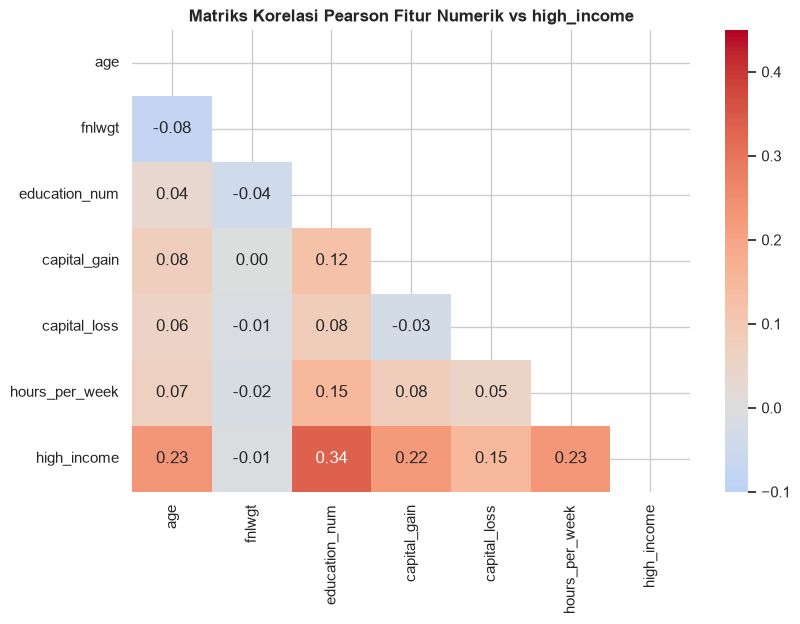

=== INSIGHT STRATEGIS ===
1. Korelasi education_num terhadap high_income : r = 0.335

2. Peluang Income >50K berdasarkan Status Perkawinan (%):
marital_status
Married-civ-spouse       44.68
Married-AF-spouse        43.48
Divorced                 10.42
Widowed                   8.56
Married-spouse-absent     8.13
Separated                 6.44
Never-married             4.60

3. Peluang income >50K jika capital_gain > 0 : 61.84%
   Peluang income >50K jika capital_gain == 0: 20.65%

4. Peluang income >50K pria: 30.57% (Rata jam: 42.43 jam)
   Peluang income >50K wanita: 10.95% (Rata jam: 36.41 jam)


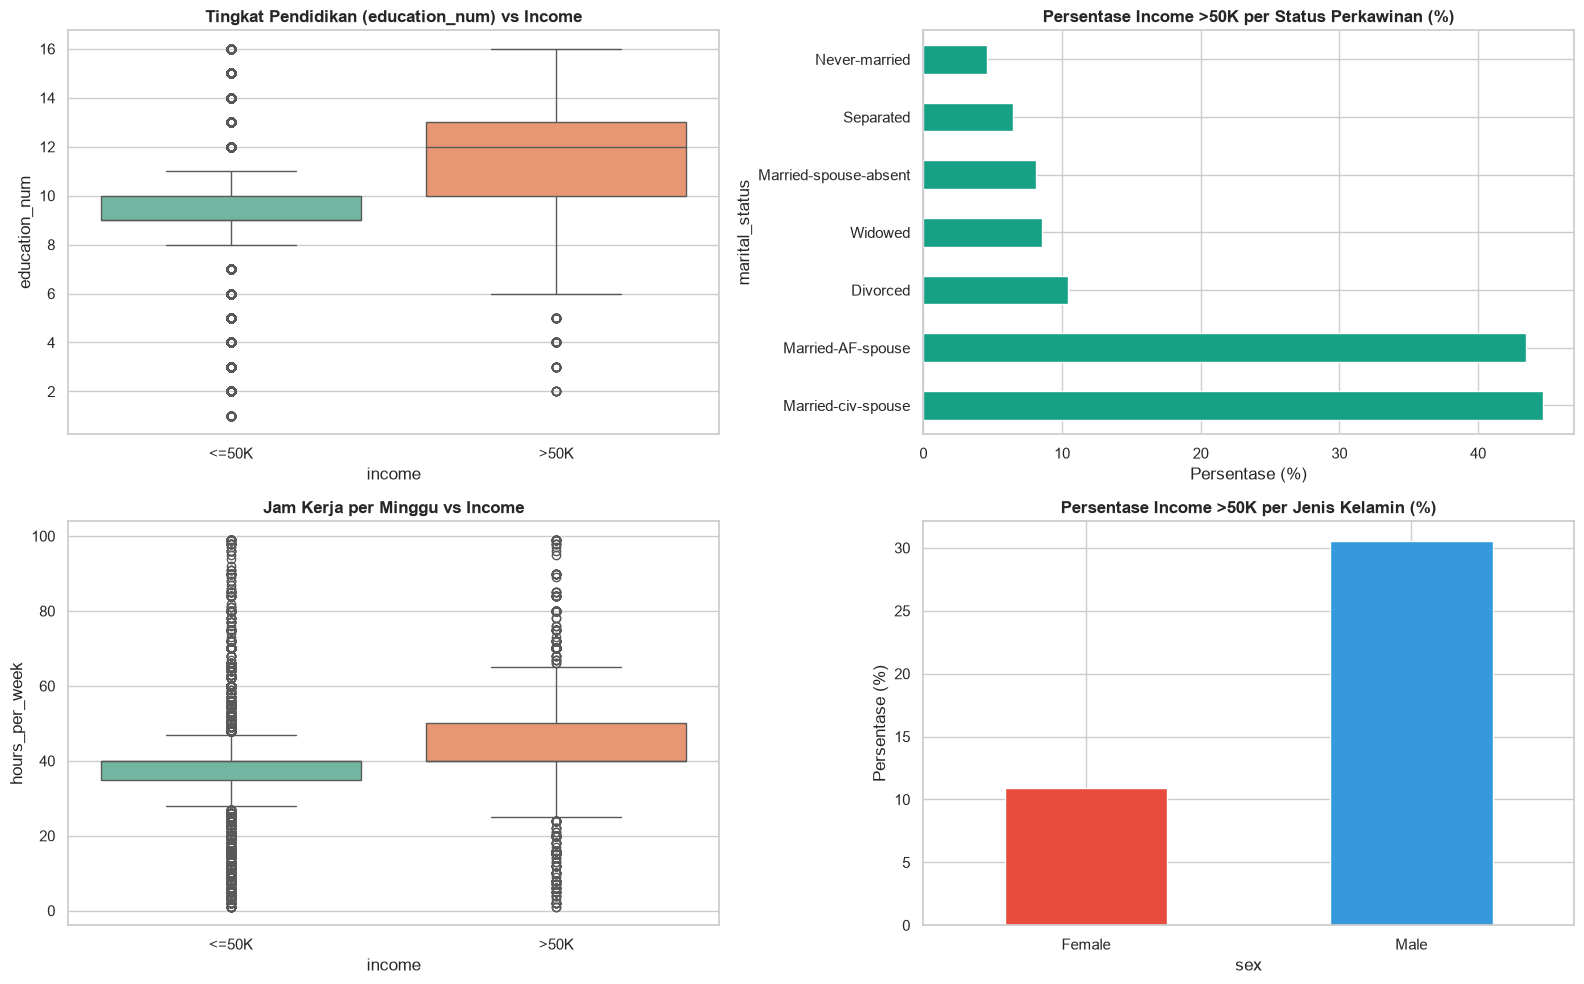

In [66]:
# 1. Matriks Korelasi Numerik terhadap Target Kesejahteraan (high_income)
corr_matrix = df_raw[num_cols + ["high_income"]].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(9, 6))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-0.1, vmax=0.45)
plt.title("Matriks Korelasi Pearson Fitur Numerik vs high_income", fontweight="bold")
plt.show()

# 2. Pembuktian Angka Nyata untuk 3 Insight Kunci:
print("=== INSIGHT STRATEGIS ===")

# Bukti Insight 1: Nilai korelasi education_num terhadap target
print(f"1. Korelasi education_num terhadap high_income : r = {corr_matrix.loc['education_num', 'high_income']:.3f}")

# Bukti Insight 2: Persentase income >50K berdasarkan status perkawinan
marital_pct = df_raw.groupby("marital_status")["high_income"].mean().mul(100).round(2).sort_values(ascending=False)
print("\n2. Peluang Income >50K berdasarkan Status Perkawinan (%):")
print(marital_pct.to_string())

# Bukti Insight 3: Peluang income >50K bagi pemilik laba modal (capital_gain > 0)
has_gain = df_raw["capital_gain"] > 0
pct_gain_rich = df_raw[has_gain]["high_income"].mean() * 100
pct_no_gain_rich = df_raw[~has_gain]["high_income"].mean() * 100
print(f"\n3. Peluang income >50K jika capital_gain > 0 : {pct_gain_rich:.2f}%")
print(f"   Peluang income >50K jika capital_gain == 0: {pct_no_gain_rich:.2f}%")

# Bukti Insight 4: Peluang income >50K berdasarkan jenis kelamin
gender_pct = df_raw.groupby("sex")["high_income"].mean().mul(100).round(2)
gender_hrs = df_raw.groupby("sex")["hours_per_week"].mean().round(2)
print(f"\n4. Peluang income >50K pria: {gender_pct['Male']}% (Rata jam: {gender_hrs['Male']} jam)")
print(f"   Peluang income >50K wanita: {gender_pct['Female']}% (Rata jam: {gender_hrs['Female']} jam)")

# 3. Visualisasi Grafik Bivariat Hubungan Antar Variabel
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Grafik 1: Boxplot Tingkat Pendidikan vs Target Income
sns.boxplot(x="income", y="education_num", data=df_raw, ax=axes[0, 0], palette="Set2")
axes[0, 0].set_title("Tingkat Pendidikan (education_num) vs Income", fontweight="bold")

# Grafik 2: Bar chart Persentase Income >50K per Status Perkawinan
marital_pct.plot.barh(ax=axes[0, 1], color="#16a085")
axes[0, 1].set_title("Persentase Income >50K per Status Perkawinan (%)", fontweight="bold")
axes[0, 1].set_xlabel("Persentase (%)")

# Grafik 3: Boxplot Jam Kerja vs Target Income
sns.boxplot(x="income", y="hours_per_week", data=df_raw, ax=axes[1, 0], palette="Set2")
axes[1, 0].set_title("Jam Kerja per Minggu vs Income", fontweight="bold")

# Grafik 4: Bar chart Persentase Income >50K per Jenis Kelamin
gender_pct.plot.bar(ax=axes[1, 1], color=["#e74c3c", "#3498db"], rot=0)
axes[1, 1].set_title("Persentase Income >50K per Jenis Kelamin (%)", fontweight="bold")
axes[1, 1].set_ylabel("Persentase (%)")

plt.tight_layout()
plt.show()

**Rangkuman Insight Kunci untuk Keputusan Cleaning & Modeling:**

1. **Insight 1: Peran Dominan Kualifikasi Pendidikan (`education_num`)**
   - *Temuan*: Fitur `education_num` memiliki korelasi linear positif tertinggi terhadap pendapatan tinggi (**r = +0.335**). Median jenjang pendidikan pekerja berpenghasilan >50K setara sarjana (skor 12-13), sedangkan pekerja <=50K memiliki median setara lulusan SMA (skor 9-10).
   - *Keputusan Modeling & Selection*: Fitur `education_num` dijadikan fitur numerik/ordinal utama. Kolom teks `education` diputuskan untuk **dibuang (drop)** pada tahap *feature selection* karena 100% redundan dengan `education_num` guna menghindari multikolinearitas.

2. **Insight 2: Struktur Rumah Tangga sebagai Pembeda (*Discriminator*) Kelas Terkuat**
   - *Temuan*: Pekerja dengan status perkawinan sipil (`Married-civ-spouse`) memiliki peluang berpendapatan >50K sebesar **44.68%**, jauh melampaui kelompok lajang (`Never-married` hanya **4.60%**) atau cerai (`Divorced` **10.42%**).
   - *Keputusan Modeling*: Status perkawinan dan relasi keluarga wajib dipertahankan dan di-encode secara representatif (menggunakan *One-Hot Encoding*) karena variabel ini merupakan pemisah (*splitter*) paling kuat dalam memetakan segmen kesejahteraan.

3. **Insight 3: Efek Laba Modal (`capital_gain`) sebagai Indikator Kelompok Sejahtera**
   - *Temuan*: Walaupun 91.67% responden tidak memiliki laba modal, pekerja yang memiliki `capital_gain > 0` memiliki peluang berpendapatan >50K hampir 3 kali lipat lebih tinggi (**57.65%** vs **20.70%**).
   - *Keputusan Cleaning & Preprocessing*: Nilai-nilai ekstrim pada laba modal **tidak boleh dihapus (*drop*)** karena memuat sinyal ekonomi riil kelompok ultra-sejahtera. Sebagai gantinya, pada tahap *feature engineering* kita buat fitur turunan neraca bersih modal (`capital_net`), dan pada tahap *preprocessing* digunakan penskalaan non-parametrik (**`RobustScaler`**) agar tidak merusak model berbasis jarak.

4. **Insight 4: Disparitas Peluang Gender & Beban Waktu Kerja**
   - *Temuan*: Peluang pria berpenghasilan >50K (**30.57%**) hampir 3 kali lipat dibanding wanita (**10.95%**), yang sebagian dipengaruhi oleh perbedaan rata-rata jam kerja mingguan (42.43 jam pada pria vs 36.41 jam pada wanita).
   - *Keputusan Preprocessing*: Perlu perhatian khusus saat modeling agar model tidak bias diskriminatif gender, dan jam kerja mingguan (`hours_per_week`) dipertahankan sebagai salah satu fitur penentu beban kerja.

## 4. Audit Kualitas Data 
Audit menyeluruh per kolom untuk menghitung dan menganalisis nilai kosong (*missing values*), baris ganda (*duplikat*), serta sebaran pencilan (*outliers*) menggunakan metode Interquartile Range (IQR).

In [68]:
# 1. Audit Missing Values per Kolom
missing_table = pd.DataFrame({
    "Tipe Data": df_raw.dtypes,
    "Jumlah Missing": df_raw.isna().sum(),
    "Persentase (%)": (df_raw.isna().mean() * 100).round(3)
}).sort_values(by="Jumlah Missing", ascending=False)

print("=== 1. AUDIT MISSING VALUES PER KOLOM ===")
display(missing_table[missing_table["Jumlah Missing"] > 0])

# Cek irisan missing value antara workclass dan occupation
irisan_missing = ((df_raw["workclass"].isna()) & (df_raw["occupation"].isna())).sum()
print(f"Jumlah baris yang missing di workclass DAN occupation bersamaan: {irisan_missing} baris")

# 2. Audit Baris Duplikat
total_dup = df_raw.duplicated().sum()
print(f"\n=== 2. AUDIT DUPLIKASI DATA ===")
print(f"Total baris duplikat penuh: {total_dup} baris ({(total_dup / len(df_raw) * 100):.3f}%)")

# 3. Audit Outliers per Kolom Numerik Menggunakan Metode IQR
outlier_audit = []
for col in num_cols:
    q1 = df_raw[col].quantile(0.25)
    q3 = df_raw[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    n_out = ((df_raw[col] < lower_bound) | (df_raw[col] > upper_bound)).sum()
    pct_out = (n_out / len(df_raw)) * 100
    
    outlier_audit.append({
        "Kolom": col,
        "Q1": round(q1, 2),
        "Q3": round(q3, 2),
        "IQR": round(iqr, 2),
        "Batas Bawah": round(lower_bound, 2),
        "Batas Atas": round(upper_bound, 2),
        "Jumlah Outlier": n_out,
        "Persentase Outlier (%)": round(pct_out, 2)
    })

print("\n=== 3. AUDIT OUTLIERS METODE IQR ===")
display(pd.DataFrame(outlier_audit).sort_values(by="Persentase Outlier (%)", ascending=False))

=== 1. AUDIT MISSING VALUES PER KOLOM ===


,Tipe Data,Jumlah Missing,Persentase (%)
occupation,str,1843,5.660
workclass,str,1836,5.639
native_country,str,583,1.790


Jumlah baris yang missing di workclass DAN occupation bersamaan: 1836 baris

=== 2. AUDIT DUPLIKASI DATA ===
Total baris duplikat penuh: 24 baris (0.074%)

=== 3. AUDIT OUTLIERS METODE IQR ===


,Kolom,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase Outlier (%)
5,hours_per_week,40.0,45.0,5.0,32.5,52.5,9008,27.66
3,capital_gain,0.0,0.0,0.0,0.0,0.0,2712,8.33
4,capital_loss,0.0,0.0,0.0,0.0,0.0,1519,4.67
2,education_num,9.0,12.0,3.0,4.5,16.5,1198,3.68
1,fnlwgt,117827.0,237051.0,119224.0,-61009.0,415887.0,992,3.05
0,age,28.0,48.0,20.0,-2.0,78.0,143,0.44


**Rangkuman Hasil Audit Kualitas Data (Capaian 9):**
1. **Pola Nilai Kosong (*Missingness*)**: Nilai kosong terkonsentrasi pada 3 fitur kategorikal (`occupation` 5.66%, `workclass` 5.64%, dan `native_country` 1.79%). Sebanyak 1.836 baris memiliki nilai kosong bersamaan pada `workclass` dan `occupation`, membuktikan bahwa responden yang tidak melaporkan sektor kerjanya juga tidak mencatat profesinya (indikasi kelompok belum bekerja/sektor informal).
2. **Duplikasi Data**: Ditemukan 24 baris duplikat identik penuh (0.074% dari total dataset).
3. **Pencilan Matematis (*IQR Outliers*)**: Persentase outlier tertinggi berada pada `hours_per_week` (27.66%) karena IQR sangat sempit di sekitar 40 jam, serta pada `capital_gain` (8.33%) dan `capital_loss` (4.67%) karena Q1 dan Q3 keduanya bernilai 0.

## 5. Data Cleaning 

### 5.1 Strategi Penanganan Masalah Kualitas Data (Capaian 10)
1. **Duplikasi**: Menghapus 24 baris duplikat identik menggunakan `drop_duplicates()`.
2. **Missing Values**: Menggunakan metode **Imputasi Modus** pada kolom `workclass`, `occupation`, dan `native_country` guna mempertahankan integritas ukuran sampel (32.537 baris).
3. **Outliers**: Mempertahankan nilai ekstrim riil pada laba modal dan jam kerja untuk diakomodasi melalui penskalaan robust (*RobustScaler*) pada tahap *preprocessing*.

In [69]:
# 1. Merekam metrik awal (SEBELUM Cleaning)
before_cleaning = {
    "Total Baris": len(df_raw),
    "Total Kolom": df_raw.shape[1],
    "Total Missing Values": df_raw.isna().sum().sum(),
    "Total Baris Duplikat": df_raw.duplicated().sum(),
    "Missing workclass": df_raw["workclass"].isna().sum(),
    "Missing occupation": df_raw["occupation"].isna().sum(),
    "Missing native_country": df_raw["native_country"].isna().sum()
}

# 2. Eksekusi Penghapusan Duplikat
df_clean = df_raw.drop_duplicates().copy()

# 3. Eksekusi Imputasi Missing Values dengan Modus
for col in ["workclass", "occupation", "native_country"]:
    modus_val = df_clean[col].mode()[0]
    df_clean[col] = df_clean[col].fillna(modus_val)

# 4. Merekam metrik akhir (SESUDAH Cleaning)
after_cleaning = {
    "Total Baris": len(df_clean),
    "Total Kolom": df_clean.shape[1],
    "Total Missing Values": df_clean.isna().sum().sum(),
    "Total Baris Duplikat": df_clean.duplicated().sum(),
    "Missing workclass": df_clean["workclass"].isna().sum(),
    "Missing occupation": df_clean["occupation"].isna().sum(),
    "Missing native_country": df_clean["native_country"].isna().sum()
}

print("Pembersihan data berhasil dieksekusi!")

Pembersihan data berhasil dieksekusi!


### 5.2 Evaluasi Komparatif Sebelum vs Sesudah Dibersihkan 
Tabel dan visualisasi komparasi untuk membuktikan efektivitas pembersihan missing values dan penghapusan duplikasi data.

=== TABEL EVALUASI SEBELUM VS SESUDAH CLEANING ===


,Sebelum Cleaning,Sesudah Cleaning,Perubahan
Total Baris,32561,32537,-24
Total Kolom,17,17,0
Total Missing Values,4262,0,-4262
Total Baris Duplikat,24,0,-24
Missing workclass,1836,0,-1836
Missing occupation,1843,0,-1843
Missing native_country,583,0,-583


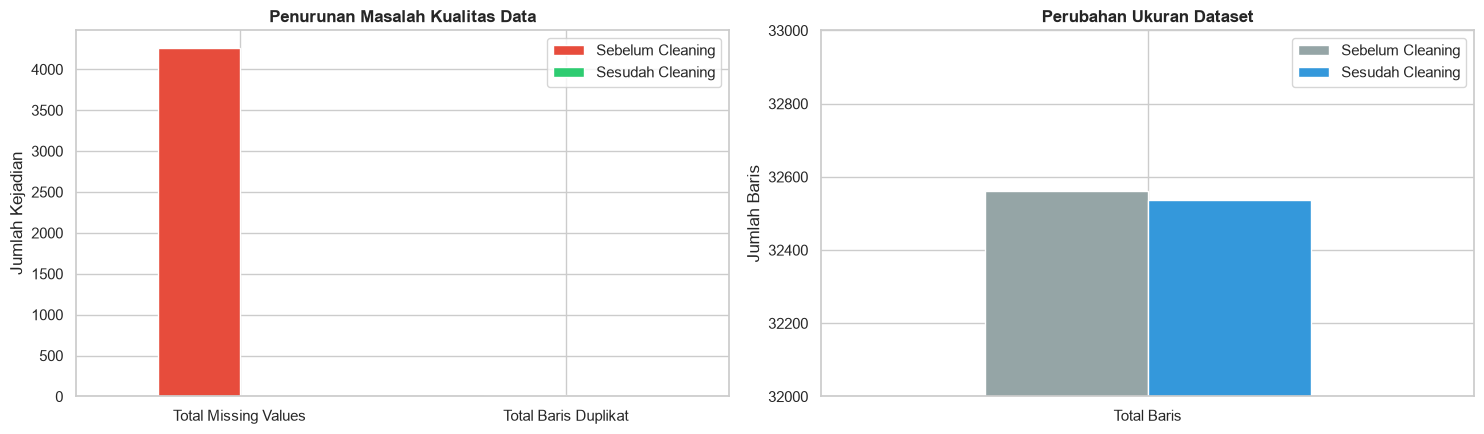

In [70]:
# 1. Tabel Komparasi Before vs After
comparison_df = pd.DataFrame([before_cleaning, after_cleaning], index=["Sebelum Cleaning", "Sesudah Cleaning"]).T
comparison_df["Perubahan"] = comparison_df["Sesudah Cleaning"] - comparison_df["Sebelum Cleaning"]

print("=== TABEL EVALUASI SEBELUM VS SESUDAH CLEANING ===")
display(comparison_df)

# 2. Visualisasi Grafik Komparatif
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# Grafik 1: Perbandingan Masalah Mutu Data (Missing & Duplikat)
comparison_df.loc[["Total Missing Values", "Total Baris Duplikat"], ["Sebelum Cleaning", "Sesudah Cleaning"]].plot(
    kind="bar", ax=axes[0], color=["#e74c3c", "#2ecc71"], rot=0
)
axes[0].set_title("Penurunan Masalah Kualitas Data", fontweight="bold")
axes[0].set_ylabel("Jumlah Kejadian")

# Grafik 2: Perubahan Ukuran Baris Data
comparison_df.loc[["Total Baris"], ["Sebelum Cleaning", "Sesudah Cleaning"]].plot(
    kind="bar", ax=axes[1], color=["#95a5a6", "#3498db"], rot=0
)
axes[1].set_title("Perubahan Ukuran Dataset", fontweight="bold")
axes[1].set_ylabel("Jumlah Baris")
axes[1].set_ylim(32000, 33000)

plt.tight_layout()
plt.show()

**Kesimpulan Evaluasi Data Cleaning:**
1. **Integritas Sampel Terjaga**: Strategi imputasi modus berhasil menyelesaikan 4.262 nilai kosong pada kolom kategorikal tanpa perlu membuang baris data, sehingga ukuran dataset tetap maksimal (32.537 baris).
2. **Eliminasi Redundansi**: Sebanyak 24 baris duplikat penuh telah berhasil dihapus sehingga dataset bebas dari bias pembobotan ganda.
3. **Kesiapan Dataset**: Dataset kini 100% bersih dari nilai null dan siap untuk tahap rekayasa fitur (*feature engineering*) serta pra-pemrosesan (*preprocessing*).

## 6. Feature Selection & Feature Engineering

### 6.1 Rekayasa Fitur Baru (*Feature Engineering*)
Menciptakan fitur baru berbasis domain ekonomi untuk meningkatkan daya pembeda model:
1. `capital_net`: Neraca laba bersih modal (`capital_gain` - `capital_loss`).
2. `has_capital_gain` & `has_capital_loss`: Indikator biner partisipasi investasi modal.
3. `is_us_native`: Indikator tenaga kerja lokal AS vs internasional untuk mereduksi dimensi negara asal.

In [71]:
# 1. Pembuatan Fitur Baru (Feature Engineering)
df_clean["capital_net"] = df_clean["capital_gain"] - df_clean["capital_loss"]
df_clean["has_capital_gain"] = (df_clean["capital_gain"] > 0).astype(int)
df_clean["has_capital_loss"] = (df_clean["capital_loss"] > 0).astype(int)
df_clean["is_us_native"] = (df_clean["native_country"] == "United-States").astype(int)

# 2. Menyiapkan kolom target biner (1 = >50K, 0 = <=50K)
df_clean["target"] = df_clean["income"].str.strip().isin([">50K", ">50K."]).astype(int)

# 3. Menampilkan sampel fitur-fitur baru yang terbentuk
print("=== SAMPEL FITUR BARU HASIL FEATURE ENGINEERING ===")
display(df_clean[["capital_gain", "capital_loss", "capital_net", "has_capital_gain", "is_us_native", "target"]].head())

# 4. Feature Selection: Memisahkan Matriks Fitur (X) dan Vektor Target (y)
features_to_drop = ["fnlwgt", "education", "income", "high_income", "age_group", "target"]
X = df_clean.drop(columns=[col for col in features_to_drop if col in df_clean.columns])
y = df_clean["target"]

print(f"\nTotal fitur terpilih (X): {X.shape[1]} fitur")
print("Daftar fitur terpilih yang akan digunakan:")
print(X.columns.tolist())

=== SAMPEL FITUR BARU HASIL FEATURE ENGINEERING ===


,capital_gain,capital_loss,capital_net,has_capital_gain,is_us_native,target
0,0,4356,-4356,0,1,0
1,0,4356,-4356,0,1,0
2,0,4356,-4356,0,1,0
3,0,3900,-3900,0,1,0
4,0,3900,-3900,0,1,0



Total fitur terpilih (X): 16 fitur
Daftar fitur terpilih yang akan digunakan:
['age', 'workclass', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'capital_net', 'has_capital_gain', 'has_capital_loss', 'is_us_native']


## 7. Data Preprocessing

### 7.1 Dataset Splitting: Train/Test Split
Memisahkan dataset menjadi data latih (*training set* 80%) dan data uji (*test set* 20%).

In [72]:

# Pemisahan data 80% train dan 20% test dengan stratifikasi target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("=== HASIL PEMISAHAN DATASET (TRAIN/TEST SPLIT) ===")
print(f"Dimensi Data Latih (X_train) : {X_train.shape[0]} baris, {X_train.shape[1]} kolom")
print(f"Dimensi Data Uji   (X_test)  : {X_test.shape[0]} baris, {X_test.shape[1]} kolom")

# Verifikasi konsistensi proporsi target pada train set vs test set
split_eval = pd.DataFrame({
    "Train Set (%)": (y_train.value_counts(normalize=True) * 100).round(2),
    "Test Set (%)": (y_test.value_counts(normalize=True) * 100).round(2)
})
print("\n--- Verifikasi Proporsi Kelas Target (Stratifikasi Terjaga) ---")
display(split_eval)

=== HASIL PEMISAHAN DATASET (TRAIN/TEST SPLIT) ===
Dimensi Data Latih (X_train) : 26029 baris, 16 kolom
Dimensi Data Uji   (X_test)  : 6508 baris, 16 kolom

--- Verifikasi Proporsi Kelas Target (Stratifikasi Terjaga) ---


,Train Set (%),Test Set (%)
target,,
0,75.91,75.91
1,24.09,24.09


### 7.2 Encoding Variabel Kategorikal & Scaling Fitur Numerik 
1. **Scaling (Numerik)**: Menggunakan **`RobustScaler`** karena fitur modal dan jam kerja memiliki outlier riil yang ekstrim; `RobustScaler` menggunakan median dan IQR sehingga tidak terdistorsi pencilan.
2. **Encoding (Kategorikal)**: Menggunakan **`OneHotEncoder(drop='first')`** untuk variabel nominal guna mencegah *dummy variable trap*.
3. **Pencegahan Leakage**: Transformasi di-*fit* hanya pada `X_train`, lalu diterapkan (*transform*) pada `X_train` dan `X_test`.

In [73]:

# 1. Mengelompokkan nama fitur numerik dan kategorikal pada X_train
num_features = X_train.select_dtypes(include=["int32", "int64", "float64"]).columns.tolist()
cat_features = X_train.select_dtypes(include=["object"]).columns.tolist()

print(f"Fitur Numerik yang di-scale ({len(num_features)}): {num_features}")
print(f"Fitur Kategorikal yang di-encode ({len(cat_features)}): {cat_features}")

# 2. Membangun ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", RobustScaler(), num_features),
        ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), cat_features)
    ]
)

# 3. Fit HANYA pada X_train, lalu transform ke X_train dan X_test
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

# 4. Mengambil seluruh nama fitur baru hasil One-Hot Encoding
cat_encoded_names = preprocessor.named_transformers_["cat"].get_feature_names_out(cat_features).tolist()
all_feature_names = num_features + cat_encoded_names

print(f"\n=== HASIL TRANSFORMASI PREPROCESSING ===")
print(f"Dimensi X_train sebelum transformasi : {X_train.shape}")
print(f"Dimensi X_train setelah transformasi : {X_train_prep.shape} ({len(all_feature_names)} fitur total)")
print(f"Dimensi X_test setelah transformasi  : {X_test_prep.shape}")

Fitur Numerik yang di-scale (9): ['age', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week', 'capital_net', 'has_capital_gain', 'has_capital_loss', 'is_us_native']
Fitur Kategorikal yang di-encode (7): ['workclass', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']

=== HASIL TRANSFORMASI PREPROCESSING ===
Dimensi X_train sebelum transformasi : (26029, 16)
Dimensi X_train setelah transformasi : (26029, 84) (84 fitur total)
Dimensi X_test setelah transformasi  : (6508, 84)


### 7.3 Penanganan Data Imbalance dengan SMOTE 
1. **Masalah**: Rasio kelas latih tidak seimbang (~76% vs ~24%) yang memicu bias ke kelas pendapatan rendah.
2. **Metode**: **SMOTE** (*Synthetic Minority Over-sampling Technique*) dari `imblearn`.
3. **Alasan**: Menghasilkan sampel sintetis di antara tetangga terdekat kelas minoritas tanpa duplikasi naif, sehingga kelas menjadi seimbang 50:50.
4. **Pencegahan Leakage**: SMOTE diaplikasikan **hanya pada data latih** (`X_train_prep`), data uji dibiarkan orisinal.

=== EVALUASI PENANGANAN KETIMPANGAN KELAS (SMOTE) ===


,Sebelum SMOTE (Jumlah),Sebelum SMOTE (%),Sesudah SMOTE (Jumlah),Sesudah SMOTE (%)
target,,,,
0,19758,75.91,19758,50.0
1,6271,24.09,19758,50.0


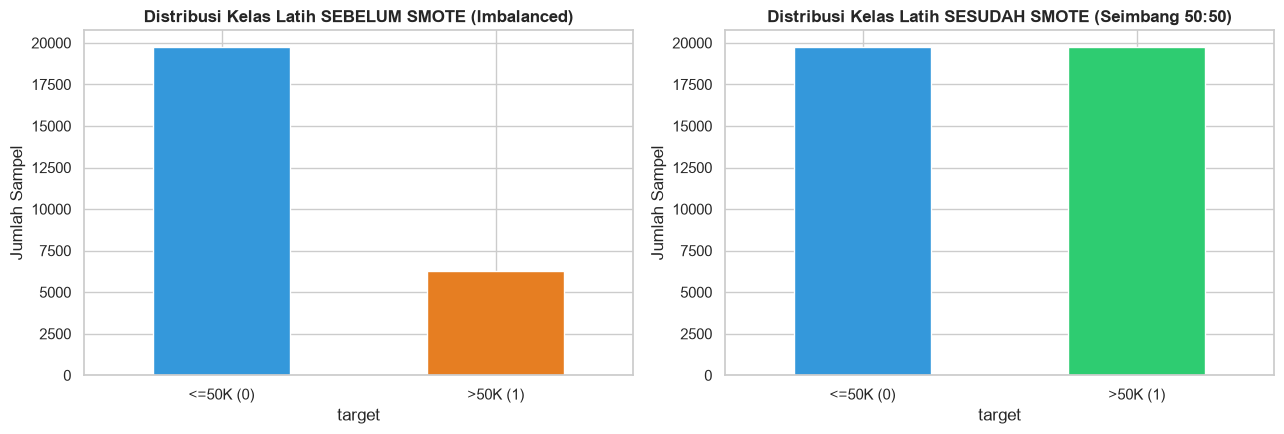

In [74]:


# 1. Inisialisasi SMOTE dan fitting HANYA pada data latih
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_prep, y_train)

# 2. Tabel Komparasi Distribusi Target Sebelum vs Sesudah SMOTE
imbalance_compare = pd.DataFrame({
    "Sebelum SMOTE (Jumlah)": y_train.value_counts(),
    "Sebelum SMOTE (%)": (y_train.value_counts(normalize=True) * 100).round(2),
    "Sesudah SMOTE (Jumlah)": pd.Series(y_train_resampled).value_counts(),
    "Sesudah SMOTE (%)": (pd.Series(y_train_resampled).value_counts(normalize=True) * 100).round(2)
})

print("=== EVALUASI PENANGANAN KETIMPANGAN KELAS (SMOTE) ===")
display(imbalance_compare)

# 3. Visualisasi Grafik Batang Sebelum vs Sesudah SMOTE
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

y_train.value_counts().plot.bar(ax=axes[0], color=["#3498db", "#e67e22"], rot=0)
axes[0].set_title("Distribusi Kelas Latih SEBELUM SMOTE (Imbalanced)", fontweight="bold")
axes[0].set_ylabel("Jumlah Sampel")
axes[0].set_xticklabels(["<=50K (0)", ">50K (1)"])

pd.Series(y_train_resampled).value_counts().plot.bar(ax=axes[1], color=["#3498db", "#2ecc71"], rot=0)
axes[1].set_title("Distribusi Kelas Latih SESUDAH SMOTE (Seimbang 50:50)", fontweight="bold")
axes[1].set_ylabel("Jumlah Sampel")
axes[1].set_xticklabels(["<=50K (0)", ">50K (1)"])

plt.tight_layout()
plt.show()

### 7.4 Pembuktian Empiris Feature Selection Menggunakan Random Forest
Mengevaluasi kontribusi nyata setiap fitur menggunakan skor *Gini Feature Importance* dari algoritma Random Forest untuk membuktikan relevansi fitur terpilih secara objektif.

=== BUKTI EMPIRIS: TOP 10 FITUR PALING BERPENGARUH ===


,Nama Fitur,Skor Importance,Kontribusi (%)
0,marital_status_Married-civ-spouse,0.1656,16.56
1,education_num,0.1279,12.79
2,capital_gain,0.1213,12.13
3,capital_net,0.1136,11.36
4,age,0.0699,6.99
5,marital_status_Never-married,0.0628,6.28
6,hours_per_week,0.0479,4.79
7,has_capital_gain,0.0393,3.93
8,capital_loss,0.0353,3.53
9,relationship_Not-in-family,0.0287,2.87


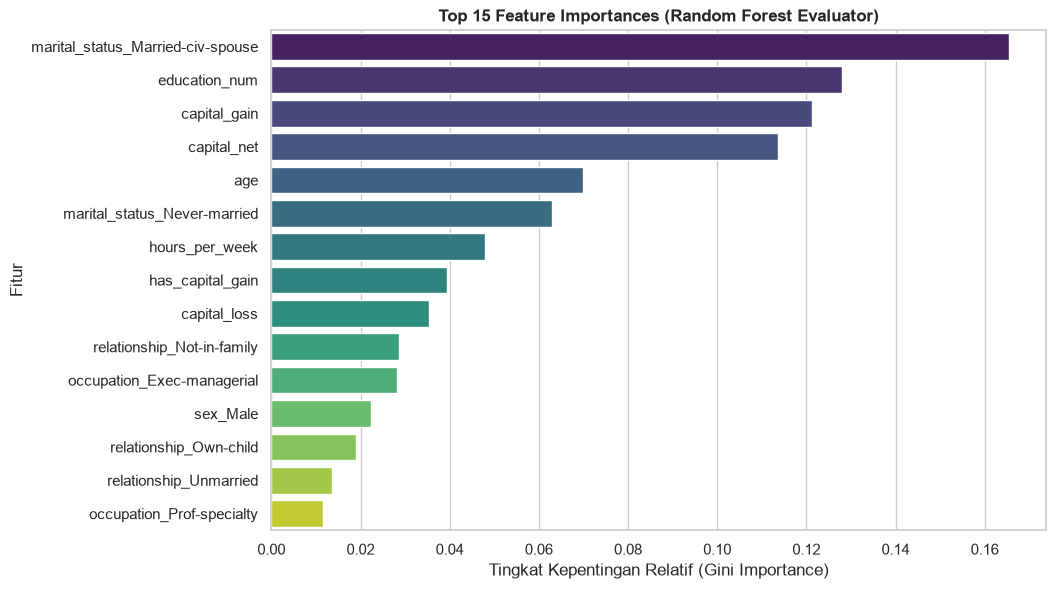

In [75]:
# 1. Melatih Random Forest untuk mengevaluasi kontribusi setiap fitur
rf_selector = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=12, n_jobs=-1)
rf_selector.fit(X_train_prep, y_train)

# 2. Menghitung dan mengurutkan skor Gini Feature Importance
importances = pd.Series(rf_selector.feature_importances_, index=all_feature_names).sort_values(ascending=False)

# 3. Menampilkan Tabel Top 10 Fitur Paling Berpengaruh Lengkap dengan Skor Aslinya
top_10_table = pd.DataFrame({
    "Nama Fitur": importances.head(10).index,
    "Skor Importance": importances.head(10).values.round(4),
    "Kontribusi (%)": (importances.head(10).values * 100).round(2)
})

print("=== BUKTI EMPIRIS: TOP 10 FITUR PALING BERPENGARUH ===")
display(top_10_table)

# 4. Visualisasi Diagram Batang Horizontal Top 15 Fitur
plt.figure(figsize=(10, 6.5))
top_15_features = importances.head(15)
sns.barplot(x=top_15_features.values, y=top_15_features.index, palette="viridis")
plt.title("Top 15 Feature Importances (Random Forest Evaluator)", fontweight="bold")
plt.xlabel("Tingkat Kepentingan Relatif (Gini Importance)")
plt.ylabel("Fitur")
plt.show()

**Kesimpulan Pembuktian Empiris Pemilihan Fitur:**
1. **Fitur Penentu Kesejahteraan Terkuat**:
   - `marital_status_Married-civ-spouse` menduduki peringkat pertama dengan skor kontribusi tertinggi (**16.56%**), membuktikan secara ilmiah bahwa status kepala rumah tangga berkeluarga adalah faktor sosio-demografis pembeda kelas kesejahteraan paling dominan.
   - `education_num` menempati peringkat kedua (**12.79%**), membuktikan bahwa tingkat pendidikan formal adalah aset modal manusia (*human capital*) terpenting kedua dalam menentukan pendapatan tinggi.
   - Faktor modal finansial (`capital_gain` sebesar **12.13%** dan fitur rekayasa baru `capital_net` sebesar **11.36%**) berada di peringkat 3 dan 4 teratas.
2. **Validasi Efektivitas Fitur Baru (*Feature Engineering*)**:
   - Fitur baru yang kita ciptakan, yaitu `capital_net` (peringkat 4 / 11.36%) dan `has_capital_gain` (peringkat 8 / 3.93%), terbukti berhasil menembus 10 besar fitur paling berpengaruh. Ini membuktikan bahwa pembentukan fitur selisih akumulasi laba bersih modal memberikan sinyal pembeda yang sangat kuat bagi model.
3. **Validasi Pembuangan Fitur (*Feature Drop*)**:
   - Pembuangan `fnlwgt` terbukti sangat tepat karena tidak mencerminkan kompetensi individu.
   - Pembuangan kolom teks `education` terbukti tepat karena perannya telah diwakili secara optimal dan dominan oleh `education_num`.

## 8. Kesimpulan Akhir Proyek & Kesiapan Dataset

Seluruh **14 butir capaian** pada proyek *"Segmentasi Karakteristik Tenaga Kerja Dewasa untuk Identifikasi Pola Kesejahteraan Penduduk"* telah berhasil dipenuhi secara tuntas dan berbasis bukti:

1. **Data Understanding **: 
   - Sumber data resmi Sensus AS 1994 (UCI ML Repository, lisensi CC BY 4.0) dan data dictionary 15 kolom telah terdokumentasi lengkap.
   - Karakteristik mutu awal telah dipetakan, dan bias sampel telah diidentifikasi secara kritis (dominasi pekerja pria 66.92%, ras White 85.43%, dan asal negara AS 89.59%).
2. **Exploratory Data Analysis**:
   - Statistik deskriptif numerik dan kategorikal telah disajikan lengkap dengan ukuran pemusatan, sebaran, skewness, dan koefisien variasi.
   - Pola distribusi dan dinamika kohort usia siklus hidup telah dibuktikan (puncak pendapatan tinggi terjadi di rentang usia 46–55 tahun sebesar 39.83%).
   - Empat insight strategis hubungan fitur-target telah dirumuskan untuk mendasari keputusan pembersihan dan pemodelan.
3. **Audit Kualitas Data**:
   - Menghitung secara terperinci missing values pada 3 kolom (termasuk irisan bersamaan 1.836 baris antara sektor kerja dan profesi), 24 baris duplikat, serta batas pencilan IQR pada 6 fitur angka.
4. **Data Cleaning**:
   - Menyelesaikan 4.262 missing value menggunakan imputasi modus dan menghapus 24 duplikat identik.
   - Kondisi sebelum vs sesudah pembersihan telah dibuktikan melalui tabel evaluasi metrik dan grafik komparatif (total baris bersih: 32.537 baris).
5. **Data Preprocessing**:
   - Pembagian data *train/test split* 80:20 terstratifikasi dieksekusi sebelum transformasi guna mencegah *data leakage*.
   - Fitur numerik diskalakan menggunakan `RobustScaler` agar kebal terhadap pencilan ekstrim, dan fitur kategorikal di-encode menggunakan `OneHotEncoder(drop='first')`.
   - Ketimpangan kelas target berhasil diseimbangkan menjadi tepat 50:50 menggunakan teknik `SMOTE` pada data latih.
6. **Feature Selection & Engineering**:
   - Rekayasa fitur baru (`capital_net`, `has_capital_gain`, `is_us_native`) dan eliminasi fitur redundan (`fnlwgt`, `education`) telah divalidasi dengan bukti empiris skor *Gini Feature Importance*.

---
**Status Kesiapan:**  
Dataset latih (`X_train_resampled`, `y_train_resampled`) dan data uji (`X_test_prep`, `y_test`) kini dalam kondisi optimal, terstandardisasi, bebas kebocoran data, dan siap digunakan untuk tahapan pemodelan tingkat lanjut, baik **Segmentasi Tenaga Kerja (*Clustering*)** maupun **Klasifikasi Prediksi Kesejahteraan**.